<a href="https://colab.research.google.com/github/akashkumar123497/CSV-FILE/blob/main/FeatureEngineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Pip install y_data profiling

In [1]:
pip install ydata_profiling

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 16.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 38.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 22.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 4.0 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
from ydata_profiling import ProfileReport
from sklearn.preprocessing import StandardScaler,LabelEncoder,OneHotEncoder,OrdinalEncoder
import warnings
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
import pickle
import warnings
warnings.filterwarnings('ignore')
%pip install --upgrade pip
%pip install --upgrade ydata-profiling

/tmp/ipykernel_1208/2625313613.py:4: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 21.9 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2


In [ ]:
pip install fg-data-profiling

In [3]:
data=pd.read_csv("/content/loan_approved (1).csv")
data

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [4]:
data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [5]:
data.tail()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y
613,LP002990,Female,No,0,Graduate,Yes,4583,0.0,133.0,360.0,0.0,Semiurban,N


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Loan_ID                 614 non-null    object 
 1   Gender                  601 non-null    object 
 2   Married                 611 non-null    object 
 3   Dependents              599 non-null    object 
 4   Education               614 non-null    object 
 5   Self_Employed           582 non-null    object 
 6   ApplicantIncome         614 non-null    int64  
 7   CoapplicantIncome       614 non-null    float64
 8   LoanAmount              592 non-null    float64
 9   Loan_Amount_Term        600 non-null    float64
 10  Credit_History          564 non-null    float64
 11  Property_Area           614 non-null    object 
 12  Loan_Status (Approved)  614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [7]:
data.shape

(614, 13)

In [8]:
data.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [9]:
data.nunique()

,0
Loan_ID,614
Gender,2
Married,2
Dependents,4
Education,2
Self_Employed,2
ApplicantIncome,505
CoapplicantIncome,287
LoanAmount,203
Loan_Amount_Term,10


In [10]:
data.isnull().sum()

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


# Imputation Methods

In [11]:
# Replacing missing values

In [12]:
# preserve sample size:Doesnt reduce data points

In [13]:
# Can introduce bias:Estimated  values might not be accurate

In [14]:
#Here are some common imputation methods

In [15]:
# Mean, Median, and Mode impuation

In [16]:
#Replacing missing values with mean, mode, median

# Imputing the null values:

In [17]:
data.loc[data['Gender'].isnull(),'Gender']='Male'

In [18]:
data.Gender.isnull().sum()

np.int64(0)

In [19]:
data.loc[data['Credit_History'].isnull(),'Credit_History']=0.0

In [20]:
data.Credit_History.isnull().sum()

np.int64(0)

In [21]:
data.loc[data['LoanAmount'].isnull(),'LoanAmount']=data['LoanAmount'].median()

In [22]:
data.LoanAmount.isnull().sum()

np.int64(0)

In [23]:
data.loc[data['Married'].isnull(),'Married']="Yes"

In [24]:
data.Married.isnull().sum()

np.int64(0)

In [25]:
data.loc[data['Self_Employed'].isnull(),'Self_Employed']="NO"

In [26]:
data.Self_Employed.isnull().sum()

np.int64(0)

In [27]:
data.loc[data['Loan_Amount_Term'].isnull(),'Loan_Amount_Term']=360.0

In [28]:
data.Loan_Amount_Term.isnull().sum()

np.int64(0)

In [29]:
data.loc[data['Dependents'].isnull(),'Dependents']='0'

In [30]:
data.Dependents.isnull().sum()

np.int64(0)

In [31]:
data.isnull().sum()

,0
Loan_ID,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0


In [32]:
# Sorting method
# Data Visualization
# Statistical outlier detection

In [33]:
data.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)'],
      dtype='object')

In [34]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Loan_ID                 614 non-null    object 
 1   Gender                  614 non-null    object 
 2   Married                 614 non-null    object 
 3   Dependents              614 non-null    object 
 4   Education               614 non-null    object 
 5   Self_Employed           614 non-null    object 
 6   ApplicantIncome         614 non-null    int64  
 7   CoapplicantIncome       614 non-null    float64
 8   LoanAmount              614 non-null    float64
 9   Loan_Amount_Term        614 non-null    float64
 10  Credit_History          614 non-null    float64
 11  Property_Area           614 non-null    object 
 12  Loan_Status (Approved)  614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


# Visualizing the Outliers

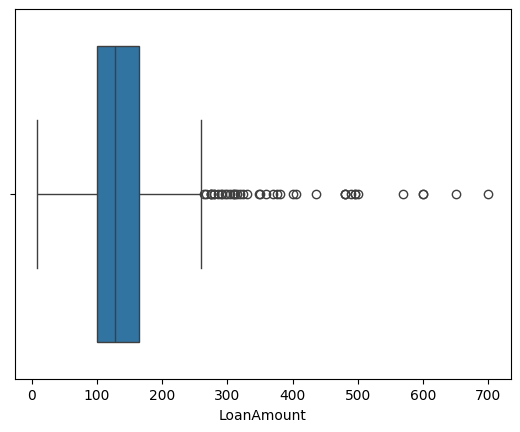

In [35]:
sns.boxplot(x='LoanAmount',data=data,orient='h')
plt.show()

# Handling the outliers using Winsorize Method to handle outliers

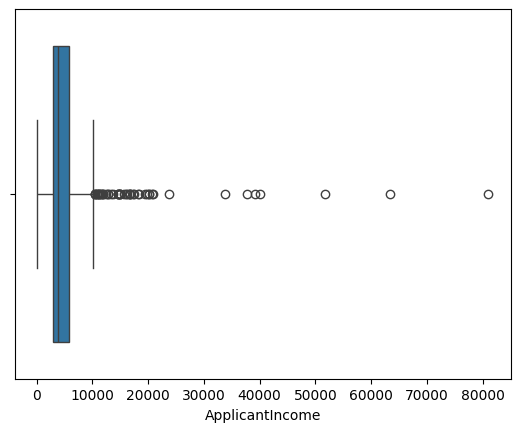

In [36]:
sns.boxplot(x='ApplicantIncome',data=data,orient='h')
plt.show()

In [37]:
from scipy.stats.mstats import winsorize

#specify the percentage of data to be trimmed from both ends
trim_percentage = 0.05

#Winsorize the specified column
data['ApplicantIncome']= winsorize(data['ApplicantIncome'], limits=trim_percentage)

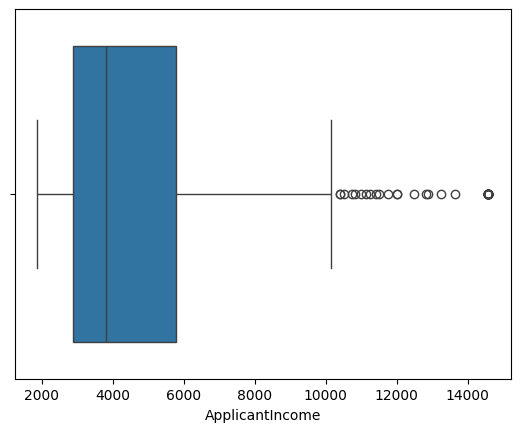

In [38]:
sns.boxplot(x='ApplicantIncome',data=data,orient='h')
plt.show()

In [39]:
#Using IQR method to handle the outliers

In [40]:
#Calculate quartiles
Q1 =data['LoanAmount'].quantile(0.25)
Q3 =data['LoanAmount'].quantile(0.75)

In [41]:
IQR = Q3 - Q1

In [42]:
# Define lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 - 1.5 * IQR

In [43]:
print(lower_bound)
print(upper_bound)

3.5
68.0


In [44]:
# Remove outliers
data = data[(data['LoanAmount'] >= lower_bound) & (data['LoanAmount'] <= upper_bound)]

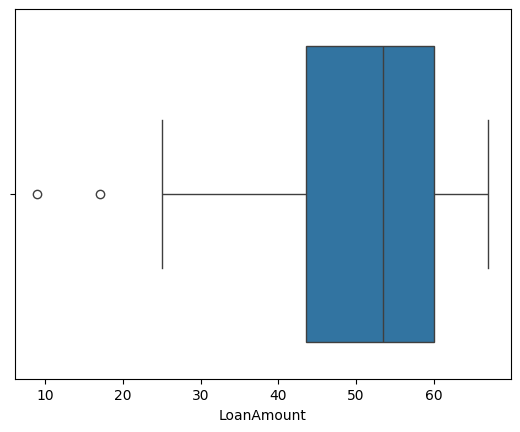

In [45]:
sns.boxplot(x='LoanAmount',data=data,orient='h')
plt.show()

In [46]:
data.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)'],
      dtype='object')

In [47]:
data['Married'].value_counts()

,count
Married,
No,26
Yes,22


In [48]:
data['Dependents'].value_counts()

,count
Dependents,
0,34
1,9
2,4
3+,1


In [49]:
data.shape

(48, 13)

In [50]:
data['Loan_Status (Approved)'].value_counts()

,count
Loan_Status (Approved),
Y,34
N,14


In [51]:
data['Property_Area'].value_counts()

,count
Property_Area,
Urban,20
Semiurban,14
Rural,14


In [52]:
#Stepe of preprocessing

# LabelEncoder for Married,credit_history
# OrdinalEncoder for Dependents,Education
# One hot encoder for Self Employed, Property_area,Gender

In [53]:
data.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)'],
      dtype='object')

In [54]:
#

In [55]:
data_encoded = pd.get_dummies(data,columns=['Married'],prefix='Married')
data

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
14,LP001030,Male,Yes,2,Graduate,No,1880,1086.0,17.0,120.0,1.0,Urban,Y
28,LP001086,Male,No,0,Not Graduate,No,1880,0.0,35.0,360.0,1.0,Urban,N
41,LP001120,Male,No,0,Graduate,No,1880,1213.0,47.0,360.0,1.0,Urban,Y
46,LP001138,Male,Yes,1,Graduate,No,5649,0.0,44.0,360.0,1.0,Urban,Y
84,LP001275,Male,Yes,1,Graduate,No,3988,0.0,50.0,240.0,1.0,Urban,Y
94,LP001325,Male,No,0,Not Graduate,No,3620,0.0,25.0,120.0,1.0,Semiurban,Y
97,LP001333,Male,Yes,0,Graduate,No,1977,997.0,50.0,360.0,1.0,Semiurban,Y
121,LP001430,Female,No,0,Graduate,No,4166,0.0,44.0,360.0,1.0,Semiurban,Y
133,LP001482,Male,Yes,0,Graduate,Yes,3459,0.0,25.0,120.0,1.0,Semiurban,Y


# Label Encoding

In [56]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

#Fit and transfrom the 'matchType' column to obtain label-encoded values
data['Married'] = encoder.fit_transform(data['Married'])

#Display the result
print(data[['Married']])

     Married
2          1
14         1
28         0
41         0
46         1
84         1
94         0
97         1
121        0
133        1
147        1
154        0
168        0
181        0
186        1
187        1
190        0
207        0
208        0
220        1
231        1
270        0
283        0
312        0
329        0
341        0
357        1
370        0
400        1
401        0
403        0
407        0
410        0
415        0
429        0
436        0
447        1
451        1
509        0
520        1
521        0
538        1
555        1
568        0
582        1
583        1
590        1
610        1


In [57]:
encoder = LabelEncoder()

#Fit and transfrom the 'matchType' column to obtain label-encoded values
data['Loan_Status (Approved)'] = encoder.fit_transform(data['Loan_Status (Approved)'])

#Display the result
print(data[['Loan_Status (Approved)']])

     Loan_Status (Approved)
2                         1
14                        1
28                        0
41                        1
46                        1
84                        1
94                        1
97                        1
121                       1
133                       1
147                       1
154                       1
168                       0
181                       0
186                       0
187                       1
190                       1
207                       1
208                       1
220                       0
231                       1
270                       1
283                       1
312                       1
329                       1
341                       0
357                       0
370                       1
400                       0
401                       0
403                       1
407                       1
410                       0
415                       1
429                 

In [58]:
data.Education.value_counts()

,count
Education,
Graduate,35
Not Graduate,13


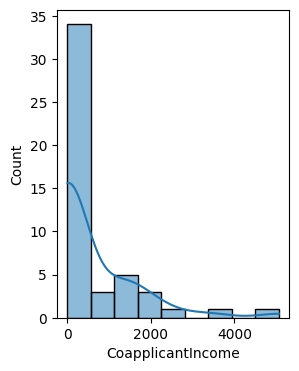

In [59]:
plt.figure(figsize=(3,4))
sns.histplot(x=data["CoapplicantIncome"],kde=True) #right skewed
plt.show()

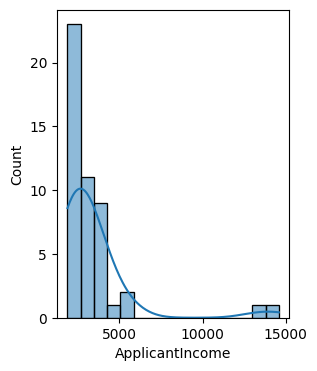

In [60]:
plt.figure(figsize=(3,4))
sns.histplot(x=data["ApplicantIncome"],kde=True) #right skewed
plt.show()

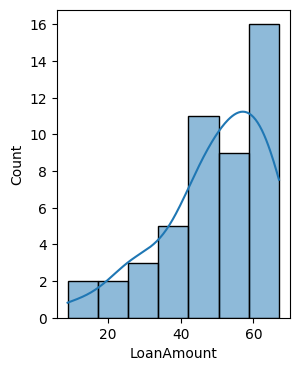

In [61]:
plt.figure(figsize=(3,4))
sns.histplot(x=data["LoanAmount"],kde=True) #left skewed
plt.show()

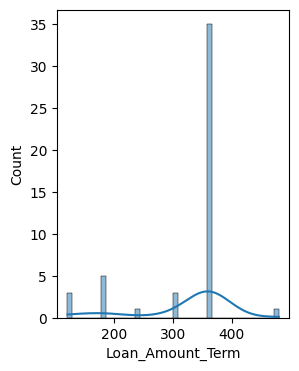

In [62]:
plt.figure(figsize=(3,4))
sns.histplot(x=data["Loan_Amount_Term"],kde=True) #left skewed
plt.show()

In [63]:
data['CoapplicantIncome']=np.log(data['CoapplicantIncome'])

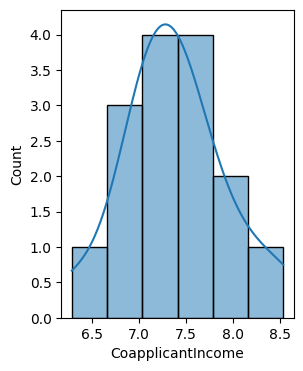

In [64]:
plt.figure(figsize=(3,4))
sns.histplot(x=data["CoapplicantIncome"],kde=True) #target columns
plt.show()

In [65]:

data['ApplicationIncome_exponential']=data.ApplicantIncome**(1/1.2)

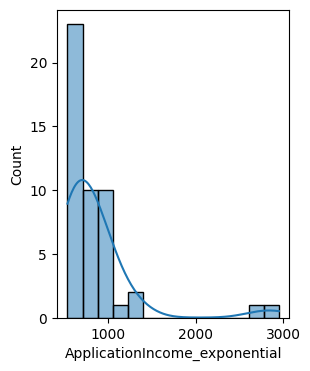

In [66]:
plt.figure(figsize=(3,4))
sns.histplot(x=data["ApplicationIncome_exponential"],kde=True) #target columns
plt.show()

In [67]:
# Box Cox Transformation
from scipy.stats import boxcox
transformed_data, lambda_value=boxcox(data['Loan_Amount_Term'])

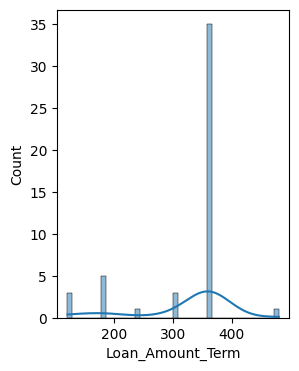

In [68]:
plt.figure(figsize=(3,4))
sns.histplot(x=data['Loan_Amount_Term'],kde=True) #target columns
plt.show()

In [69]:
print("Transformed data:",transformed_data)

Transformed data: [ 6309762.20049472   279442.19186289  6309762.20049472  6309762.20049472
  6309762.20049472  1997077.80489031   279442.19186289  6309762.20049472
  6309762.20049472   279442.19186289  6309762.20049472  6309762.20049472
 14272418.96119915  6309762.20049472  3761444.19389791  6309762.20049472
  6309762.20049472  6309762.20049472  6309762.20049472  6309762.20049472
   882897.54282319  6309762.20049472  6309762.20049472  6309762.20049472
  6309762.20049472  6309762.20049472  6309762.20049472  6309762.20049472
   882897.54282319  3761444.19389791  6309762.20049472  6309762.20049472
  6309762.20049472  6309762.20049472   882897.54282319  6309762.20049472
  6309762.20049472  3761444.19389791  6309762.20049472  6309762.20049472
  6309762.20049472  6309762.20049472  6309762.20049472  6309762.20049472
  6309762.20049472  6309762.20049472   882897.54282319   882897.54282319]


In [70]:
data['LoanAmount']=data.LoanAmount**(1/2)

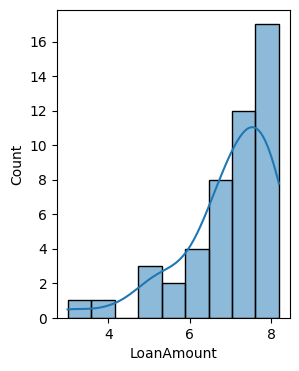

In [71]:
plt.figure(figsize=(3,4))
sns.histplot(x=data["LoanAmount"],kde=True) #target columns
plt.show()